## Data Preparation of the laboratory events dataset

In [1]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

import data_preparation_utils as du

data_frame = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")

In [2]:
# Identify rows where 'value' is not '___' but 'valuenum' is missing

mask_val = (data_frame['value'] != "___")
mask_valnum = (data_frame['valuenum'].isna())
data_frame[mask_val & mask_valnum]

,hadm_id,charttime,value,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
171,26913865.0,2189-07-02 10:20:00,NaN,NaN,NaN,NaN,NaN,NaN,EDTA Hold,Blood,EDTA Hold,BATCH_218907_Z1,OK,Normal range: 70-110
193,26913865.0,2189-07-02 10:20:00,NaN,NaN,NaN,NaN,NaN,NaN,Red Top Hold,Blood,Red Top Hold,BATCH_218907_J6,OK,NaN
330,23822395.0,2129-08-06 10:48:00,NOT INTUBATED.,NaN,NaN,NaN,NaN,NaN,Intubated,Blood,Blood Gas,BATCH_212908_B1,OK,NaN
335,23822395.0,2129-08-06 10:48:00,ART.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212908_H8,OK,Normal range: 70-110
337,23822395.0,2129-08-06 18:54:00,NaN,NaN,NaN,NaN,NaN,NaN,Length of Urine Collection,Urine,Urine Test,BATCH_212908_N2,OK,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
978242,24169669.0,2128-02-25 06:36:00,NaN,NaN,sec,25.0,36.5,NaN,PTT,Blood,Coagulation and Hemostasis,BATCH_212802_P5,OK,NaN
978247,24169669.0,2128-02-25 09:58:00,VEN.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212802_B5,WARN,Normal range: 3-5
978290,24169669.0,2128-02-26 20:00:00,ART.,NaN,NaN,NaN,NaN,NaN,Specimen Type,Blood,Blood Gas,BATCH_212802_N2,OK,Normal range: 70-110
978347,21557581.0,2145-07-26 16:14:00,NaN,NaN,NaN,NaN,NaN,NaN,Length of Urine Collection,Urine,Urine Test,BATCH_214507_F5,OK,NaN


In [3]:
#  Drop original 'value' column

data_frame=data_frame.drop(columns='value')
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,NaN,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,NaN,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,abnormal,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,abnormal,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,abnormal,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,NaN,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,NaN,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,abnormal,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,NaN,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [4]:
# Group labels by examination_group and inspect unique labels per group

grouped = data_frame.groupby('examination_group')['label'].unique()
examination_values_list = grouped.to_dict()
examination_values_list.keys()
grouped

examination_group
ADP                                                                            [ADP]
ANCA Titer                                                              [ANCA Titer]
ARCH-1                                                                      [ARCH-1]
Absolute CD3 Count                                              [Absolute CD3 Count]
Absolute CD4 Count                                              [Absolute CD4 Count]
                                                         ...                        
Urine Test                         [Length of Urine Collection, Urine tube, held,...
Virology                                                [Cytomegalovirus Viral Load]
Vitamin and Nutritional Studies    [Vitamin B12, Ferritin, Folate, Iron, Iron Bin...
Voided Specimen                                                    [Voided Specimen]
proBNP, Pleural                                                    [proBNP, Pleural]
Name: label, Length: 202, dtype: object

In [5]:
# Replace NaN flags with 0 and 'abnormal' with 1

data_frame["flag"] = data_frame["flag"].replace(np.nan, 0)
data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)
data_frame


/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_59032/1844387552.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [6]:
# Define function to compute percentage of missing values per column and print results

def get_none_percentage_per_cols(data_frame):
    res = []
    cols = du.get_cols(data_frame)
    rows = data_frame.shape[0]
    for col in cols:
        not_none = (data_frame[col].count())
        none_percentage = ((rows - not_none)/rows)*100
        res.append((col, none_percentage))
    return res
# Get the percentage of None values for each columns
none_percentage_per_cols = []

print("PERCENTAGE OF NONE PER COLUMN")
for col, percentage in sorted(get_none_percentage_per_cols(data_frame), key=lambda tup: tup[1], reverse=True):
    print(f"{col}: {percentage:.2f}%")

PERCENTAGE OF NONE PER COLUMN
ref_range: 85.06%
ref_range_lower: 11.54%
ref_range_upper: 11.54%
valueuom: 9.60%
valuenum: 7.27%
hadm_id: 0.00%
charttime: 0.00%
flag: 0.00%
label: 0.00%
fluid: 0.00%
examination_group: 0.00%
analysis_batch_id: 0.00%
qc_flag: 0.00%


In [7]:
# Merge labs with heart diagnoses to count heart disease admissions and patients

heart_diagnoses_df = pd.read_csv("../../data/processed/hd.csv")
heart_diagnoses_df_merged = pd.merge(data_frame, heart_diagnoses_df, on=['hadm_id'], how='inner')
print(f"Rows after merge: {heart_diagnoses_df_merged.shape[0]}")
print(f"Patients: {heart_diagnoses_df_merged['subject_id'].nunique()}")
heart_diagnoses_df_merged

Rows after merge: 1000811
Patients: 4385


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range,subject_id,icd_code,long_title,gender,age
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN,10000980,I50,Heart failure,F,75
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN,10000980,I50,Heart failure,F,75
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN,10000980,I50,Heart failure,F,75
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN,10000980,I50,Heart failure,F,75
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN,10000980,I50,Heart failure,F,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1000806,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66
1000807,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66
1000808,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66
1000809,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66


In [8]:
# Analyze which heart-disease patients are excluded when keeping only top 5 exam groups

print("=== ANALYSIS: Heart-disease patients excluded by filter ===\n")

df_lab_original = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")
heart_diagnoses_df = pd.read_csv("../../data/processed/hd.csv")

# Merge to get subject_id (patients)
df_with_patients = pd.merge(df_lab_original, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')

print(f"Total patients with heart diagnosis and lab events: {df_with_patients['subject_id'].nunique()}")
print(f"Total admissions: {df_with_patients['hadm_id'].nunique()}")

# Filter only the 5 main exams
main_exams = ['BMP', 'Complete Blood Count (CBC)', 'Cardiac Markers', 'Lipid Panel', 'Coagulation and Hemostasis']
df_filtered = df_with_patients[df_with_patients['examination_group'].isin(main_exams)]

patients_after_filter = df_filtered['subject_id'].unique()
patients_before_filter = df_with_patients['subject_id'].unique()

# Find excluded patients
excluded_patients = set(patients_before_filter) - set(patients_after_filter)

print(f"\nPatients after the filter (with at least 1 of the 5 exams): {len(patients_after_filter)}")
print(f"EXCLUDED patients (without any of the 5 exams): {len(excluded_patients)}")

if len(excluded_patients) > 0:
    df_excluded = df_with_patients[df_with_patients['subject_id'].isin(excluded_patients)]
    
    print(f"\n--- Which exams did the {len(excluded_patients)} excluded patients have? ---")
    excluded_exams = df_excluded['examination_group'].value_counts()
    
    for exam, count in excluded_exams.items():
        pct = (count / df_excluded.shape[0]) * 100
        print(f"{exam:40s}: {count:5d} rows ({pct:5.1f}%)")
    
    print(f"\n--- First 10 excluded patients (unique) and their exams ---")
    excluded_patients_list = sorted(list(excluded_patients))[:10]
    for patient_id in excluded_patients_list:
        patient_exams = df_excluded[df_excluded['subject_id'] == patient_id]['examination_group'].unique()
        print(f"Patient {patient_id}: {', '.join(patient_exams)}")
    
    print(f"\n✓ These {len(excluded_patients)} patients had ONLY exams not included in the top 5")

else:
    print("\n✓ No patients excluded! All have at least one of the top 5 exams")

=== ANALYSIS: Heart-disease patients excluded by filter ===

Total patients with heart diagnosis and lab events: 4385
Total admissions: 4752

Patients after the filter (with at least 1 of the 5 exams): 4382
EXCLUDED patients (without any of the 5 exams): 3

--- Which exams did the 3 excluded patients have? ---
Blood Gas                               :    37 rows ( 69.8%)
Urine Test                              :    12 rows ( 22.6%)
Red Top Hold                            :     1 rows (  1.9%)
Blue Top Hold                           :     1 rows (  1.9%)
Light Green Top Hold                    :     1 rows (  1.9%)
EDTA Hold                               :     1 rows (  1.9%)

--- First 10 excluded patients (unique) and their exams ---
Patient 14048242: Red Top Hold, Blue Top Hold, Light Green Top Hold, EDTA Hold, Blood Gas
Patient 14101636: Blood Gas
Patient 17737493: Urine Test

✓ These 3 patients had ONLY exams not included in the top 5


In [9]:
# Reload raw data, reapply initial transforms, add 'Blood Gas' to selected heart examinations and filter

data_frame = pd.read_csv("../../data/raw/laboratory_events_codes_2.csv")

data_frame = data_frame.drop(columns='value')
data_frame["flag"] = data_frame["flag"].replace(np.nan, 0)
data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)

heart_examinations = ['BMP', 'Complete Blood Count (CBC)', 'Cardiac Markers', 'Lipid Panel', 'Coagulation and Hemostasis','Blood Gas']
data_frame = data_frame[data_frame['examination_group'].isin(heart_examinations)]
print(f"Examination groups in dataset: {data_frame['examination_group'].unique()}")
data_frame

Examination groups in dataset: ['Cardiac Markers' 'Coagulation and Hemostasis' 'BMP' 'Lipid Panel'
 'Complete Blood Count (CBC)' 'Blood Gas']


/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_59032/4254448733.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_frame["flag"] = data_frame["flag"].replace("abnormal", 1)


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [10]:
# Merge filtered data with heart diagnoses and display number of unique patients

heart_diagnoses_df = pd.read_csv("../../data/processed/hd.csv")
heart_diagnoses_df_merged = pd.merge(data_frame, heart_diagnoses_df, on=['hadm_id'], how='inner')
print(f"Rows after merge: {heart_diagnoses_df_merged.shape[0]}")
print(f"Patients: {heart_diagnoses_df_merged['subject_id'].nunique()}")
heart_diagnoses_df_merged

Rows after merge: 767258
Patients: 4384


,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range,subject_id,icd_code,long_title,gender,age
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN,10000980,I50,Heart failure,F,75
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN,10000980,I50,Heart failure,F,75
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN,10000980,I50,Heart failure,F,75
3,29654838.0,2188-01-05 06:56:00,1.20,NaN,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN,10000980,I50,Heart failure,F,75
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN,10000980,I50,Heart failure,F,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
767253,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66
767254,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66
767255,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66
767256,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN,19998497,I25,Chronic ischemic heart disease,M,66


In [11]:
# For each (examination_group, label) compute missing 'valueuom' counts and inspect INR rows

grouped = data_frame.groupby(['examination_group', 'label'])

print("MISSING valueuom PER (LABEL, EXAMINATION_GROUP)")
for name, group in grouped:
    total = group.shape[0]
    missing_valueuom = group['valueuom'].isna().sum()
    missing_percentage = (missing_valueuom / total) * 100
    print(f"{name}: {missing_valueuom} missing valueuom out of {total} ({missing_percentage:.2f}%)")

inr_data = data_frame[data_frame['label'] == 'INR(PT)'][['ref_range_lower', 'ref_range_upper', 'valueuom', 'label']]
inr_data

MISSING valueuom PER (LABEL, EXAMINATION_GROUP)
('BMP', 'Bicarbonate'): 0 missing valueuom out of 34925 (0.00%)
('BMP', 'Calcium, Total'): 0 missing valueuom out of 29060 (0.00%)
('BMP', 'Chloride'): 0 missing valueuom out of 36612 (0.00%)
('BMP', 'Creatinine'): 0 missing valueuom out of 35939 (0.00%)
('BMP', 'Glucose'): 0 missing valueuom out of 34015 (0.00%)
('BMP', 'Potassium'): 0 missing valueuom out of 37859 (0.00%)
('BMP', 'Sodium'): 0 missing valueuom out of 36712 (0.00%)
('BMP', 'Urea Nitrogen'): 0 missing valueuom out of 35651 (0.00%)
('Blood Gas', 'Alveolar-arterial Gradient'): 0 missing valueuom out of 161 (0.00%)
('Blood Gas', 'Assist/Control'): 260 missing valueuom out of 260 (100.00%)
('Blood Gas', 'Base Excess'): 0 missing valueuom out of 7325 (0.00%)
('Blood Gas', 'Calculated Bicarbonate, Whole Blood'): 0 missing valueuom out of 62 (0.00%)
('Blood Gas', 'Calculated Total CO2'): 0 missing valueuom out of 7323 (0.00%)
('Blood Gas', 'Carboxyhemoglobin'): 0 missing valueuom

,ref_range_lower,ref_range_upper,valueuom,label
3,0.9,1.1,NaN,INR(PT)
64,0.9,1.1,NaN,INR(PT)
89,0.9,1.1,NaN,INR(PT)
92,0.9,1.1,NaN,INR(PT)
228,0.9,1.1,NaN,INR(PT)
...,...,...,...,...
978183,0.9,1.1,NaN,INR(PT)
978206,0.9,1.1,NaN,INR(PT)
978240,0.9,1.1,NaN,INR(PT)
978243,0.9,1.1,NaN,INR(PT)


In [12]:
# Fill missing 'valueuom' for INR(PT) with 'u'

data_frame.loc[data_frame['label'] == 'INR(PT)', 'valueuom'] = data_frame.loc[data_frame['label'] == 'INR(PT)', 'valueuom'].fillna('u')
data_frame

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,OK,NaN
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,OK,NaN
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,OK,NaN
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,OK,NaN
4,29654838.0,2188-01-05 06:56:00,12.80,sec,9.4,12.50,1,PT,Blood,Coagulation and Hemostasis,BATCH_218801_B1,WARN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,OK,NaN
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,OK,NaN
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,OK,NaN
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,OK,NaN


In [13]:
# Check uniqueness/consistency of ref_range_lower and ref_range_upper per label

nunique_check = (
    data_frame
    .groupby('label')[['ref_range_lower', 'ref_range_upper']]
    .nunique(dropna=True)
)
consistent = (nunique_check <= 1).all(axis=1)

inconsistent_labels = consistent[~consistent].index.tolist()

print("Inconsistent labels:", inconsistent_labels)


Inconsistent labels: ['Antithrombin', 'Basophils', 'Calcium, Total', 'Chloride, Whole Blood', 'Creatine Kinase (CK)', 'Creatinine', 'Eosinophils', 'Factor II', 'Factor VIII', 'Factor X', 'Fibrinogen, Functional', 'Glucose', 'Hematocrit', 'Hemoglobin', 'Lymphocytes', 'Lymphocytes, Percent', 'MCH', 'MCHC', 'Monocytes', 'NTproBNP', 'Neutrophils', 'PT', 'PTT', 'Platelet Count', 'Potassium', 'Potassium, Whole Blood', 'Protein C, Functional', 'Protein S, Functional', 'Red Blood Cells', 'Sodium', 'Sodium, Whole Blood', 'Thrombin', 'Von Willebrand Factor Antigen', 'WBC Count', 'White Blood Cells']


In [14]:
# Analyze combinations of label and reference ranges and list labels without ranges

cols = ["label", "ref_range_lower", "ref_range_upper"]
df_ranges = data_frame[cols].copy()

range_counts = (
    df_ranges
    .groupby(["label", "ref_range_lower", "ref_range_upper"], dropna=False)
    .size()
    .reset_index(name="count")
)

all_labels = set(df_ranges["label"].dropna().unique())

labels_with_ranges = set(range_counts["label"].dropna().unique())

labels_no_range = all_labels - labels_with_ranges

df_no_range = pd.DataFrame({
    "label": list(labels_no_range),
    "ref_range_lower": np.nan,
    "ref_range_upper": np.nan,
    "count": 0
})

range_counts_full = pd.concat([range_counts, df_no_range], ignore_index=True)
range_counts_full = range_counts_full.sort_values(by=["label", "count"], ascending=[True, False]).reset_index(drop=True)

for label, group in range_counts_full.groupby("label"):
    print(f"\n{label}:")
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")
        


Absolute Basophil Count:
  lower = 0.01, upper = 0.08  →  count = 855

Absolute Eosinophil Count:
  lower = 0.04, upper = 0.54  →  count = 855

Absolute Lymphocyte Count:
  lower = 1.2, upper = 3.7  →  count = 855
  lower = nan, upper = nan  →  count = 11

Absolute Monocyte Count:
  lower = 0.2, upper = 0.8  →  count = 855

Absolute Neutrophil Count:
  lower = 1.6, upper = 6.1  →  count = 855

Alveolar-arterial Gradient:
  lower = nan, upper = nan  →  count = 161

Antithrombin:
  lower = 80.0, upper = 130.0  →  count = 3
  lower = 69.0, upper = 121.0  →  count = 2

Assist/Control:
  lower = nan, upper = nan  →  count = 260

Base Excess:
  lower = nan, upper = nan  →  count = 7325

Basophils:
  lower = 0.0, upper = 2.0  →  count = 1970
  lower = 0.0, upper = 1.0  →  count = 855

Bicarbonate:
  lower = 22.0, upper = 32.0  →  count = 34925

CK-MB Index:
  lower = 0.0, upper = 6.0  →  count = 2218

Calcium, Total:
  lower = 8.4, upper = 10.3  →  count = 24617
  lower = 8.4, upper = 10.2  

In [15]:
# Identify rows where both reference ranges equal 0.0 and inspect examples

df = data_frame.copy()
df['ref_range_lower'] = pd.to_numeric(df['ref_range_lower'], errors='coerce')
df['ref_range_upper'] = pd.to_numeric(df['ref_range_upper'], errors='coerce')

mask_zero = np.isclose(df['ref_range_lower'], 0.0) & np.isclose(df['ref_range_upper'], 0.0)
print(f"Rows with both ranges = 0.0: {mask_zero.sum()}\n")

if mask_zero.sum() > 0:
    print("First unique rows (label, unit, fluid):")
    print(df.loc[mask_zero, ['label','ref_range_lower','ref_range_upper','valueuom','fluid']].drop_duplicates().head(50))
    print("\nCount per label:")
    print(df.loc[mask_zero].groupby('label').size().reset_index(name='count').sort_values('count', ascending=False).head(50))
else:
    print("No rows found.")

Rows with both ranges = 0.0: 0

No rows found.


Clean data in this order:
- Case 1: multiple numeric pairs for the same value -> search for the source
- Case 2: one numeric pair and one NaN pair -> convert the NaN pair to the numeric pair
- Case 3: multiple numeric pairs plus one or more NaN pairs -> search for the source + convert NaN pairs to numeric where possible (combine solutions from case 1 and case 2)

In [16]:
# Identify case1 labels (multiple numeric ranges for same label)
df = range_counts_full.copy()

def has_any_nan(group):
    return group["ref_range_lower"].isna().any() or group["ref_range_upper"].isna().any()

label_has_nan = df.groupby("label").apply(has_any_nan)

labels_no_nan = label_has_nan[~label_has_nan].index

df_no_nan = df[df["label"].isin(labels_no_nan)].copy()

numeric_pairs_per_label = (
    df_no_nan
    .groupby("label")
    .apply(lambda g: g[["ref_range_lower", "ref_range_upper"]].drop_duplicates().shape[0])
)

labels_case1 = numeric_pairs_per_label[numeric_pairs_per_label >= 2].index.tolist()

print(f"\n=== CASE 1: LABELS WITH ≥ 2 NUMERIC PAIRS AND NEVER NaN ===")
for label in labels_case1:
    print(f"\n{label}:")
    group = df_no_nan[df_no_nan["label"] == label]
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")


=== CASE 1: LABELS WITH ≥ 2 NUMERIC PAIRS AND NEVER NaN ===

Antithrombin:
  lower = 80.0, upper = 130.0  →  count = 3
  lower = 69.0, upper = 121.0  →  count = 2

Basophils:
  lower = 0.0, upper = 2.0  →  count = 1970
  lower = 0.0, upper = 1.0  →  count = 855

Calcium, Total:
  lower = 8.4, upper = 10.3  →  count = 24617
  lower = 8.4, upper = 10.2  →  count = 4443

Chloride, Whole Blood:
  lower = 96.0, upper = 108.0  →  count = 659
  lower = 100.0, upper = 112.0  →  count = 179

Creatine Kinase (CK):
  lower = 47.0, upper = 322.0  →  count = 3155
  lower = 29.0, upper = 201.0  →  count = 1869
  lower = 38.0, upper = 174.0  →  count = 1515
  lower = 26.0, upper = 140.0  →  count = 1033

Creatinine:
  lower = 0.5, upper = 1.2  →  count = 20919
  lower = 0.4, upper = 1.1  →  count = 15020

Eosinophils:
  lower = 0.0, upper = 4.0  →  count = 1970
  lower = 1.0, upper = 7.0  →  count = 855

Factor II:
  lower = 50.0, upper = 150.0  →  count = 1
  lower = 85.0, upper = 145.0  →  count =

/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_59032/1451240681.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  label_has_nan = df.groupby("label").apply(has_any_nan)
/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_59032/1451240681.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g[["ref_range_lower", "ref_range_upper"]].drop_duplicates().shape[0])


In [17]:
# Identify case2 labels (one numeric pair and one NaN pair)

labels_case2 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] == 1 and nan_pairs.shape[0] == 1:
        labels_case2.append(label)
print(f"\n=== CASE 2: LABELS WITH 1 NUMERIC PAIR AND 1 NaN PAIR ===")
for label in labels_case2:
    print(f"\n{label}:")
    group = df[df["label"] == label]
    for _, row in group.iterrows():
        print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")


=== CASE 2: LABELS WITH 1 NUMERIC PAIR AND 1 NaN PAIR ===

Absolute Lymphocyte Count:
  lower = 1.2, upper = 3.7  →  count = 855
  lower = nan, upper = nan  →  count = 11

Cholesterol, HDL:
  lower = nan, upper = nan  →  count = 888
  lower = 41.0, upper = 999.0  →  count = 63

D-Dimer:
  lower = 0.0, upper = 500.0  →  count = 134
  lower = nan, upper = nan  →  count = 13

pH:
  lower = 7.35, upper = 7.45  →  count = 8319
  lower = nan, upper = nan  →  count = 123


In [18]:
# Identify case3 labels (multiple numeric pairs and at least one NaN pair, excluding case1 and case2)

df = range_counts_full.copy()

labels_case1 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] >= 2 and nan_pairs.shape[0] == 0:
        labels_case1.append(label)

labels_case2 = []
for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]
    if numeric.shape[0] == 1 and nan_pairs.shape[0] == 1:
        labels_case2.append(label)

labels_case3 = []

for label, group in df.groupby("label"):
    numeric = group.dropna(subset=["ref_range_lower", "ref_range_upper"])
    nan_pairs = group[group["ref_range_lower"].isna() & group["ref_range_upper"].isna()]

    # case 3 conditions
    if (
        numeric.shape[0] >= 2                 # ≥2 numeric pairs
        and nan_pairs.shape[0] >= 1           # at least one NaN pair
        and label not in labels_case1         # not case 1
        and label not in labels_case2         # not case 2
    ):
        labels_case3.append(label)

print("\n=== CASE 3: ≥2 NUMERIC PAIRS + ≥1 NaN PAIR (excluding case1, case2, and single numeric) ===")
for label in labels_case3:
    print(f"\n{label}:")
    group = df[df["label"] == label]

    for _, row in group.iterrows():
        if pd.isna(row["ref_range_lower"]) and pd.isna(row["ref_range_upper"]):
            print(f"  lower = NaN, upper = NaN  →  count = {int(row['count'])}")
        else:
            print(f"  lower = {row['ref_range_lower']}, upper = {row['ref_range_upper']}  →  count = {int(row['count'])}")


=== CASE 3: ≥2 NUMERIC PAIRS + ≥1 NaN PAIR (excluding case1, case2, and single numeric) ===


In [19]:
# Automatically fills missing ref_range_lower/upper for each Case2 label by copying the available reference ranges from rows with the same fluid and valueuom, logging which labels were fixed and which require manual correction.

correct_labels = []

for label in labels_case2:
    mask_label = data_frame["label"] == label
    label_updated = False

    rows_with_range = data_frame[mask_label & ~data_frame["ref_range_lower"].isna()]

    rows_with_nan = data_frame[
        mask_label
        & data_frame["ref_range_lower"].isna()
        & data_frame["ref_range_upper"].isna()
    ]

    # For each distinct (fluid, valueuom) combination in the rows with numeric ranges
    for (fluid, valueuom) in rows_with_range[["fluid", "valueuom"]].drop_duplicates().itertuples(index=False):
        # Find the range for this specific combination
        range_row = rows_with_range[
            (rows_with_range["fluid"] == fluid)
            & (rows_with_range["valueuom"] == valueuom)
        ].iloc[0]
        lower_value = range_row["ref_range_lower"]
        upper_value = range_row["ref_range_upper"]

        # Update ONLY the NaN rows that have the SAME fluid and valueuom
        mask_to_update = (
            mask_label
            & data_frame["ref_range_lower"].isna()
            & data_frame["ref_range_upper"].isna()
            & (data_frame["fluid"] == fluid)
            & (data_frame["valueuom"] == valueuom)
        )

        data_frame.loc[mask_to_update, "ref_range_lower"] = lower_value
        data_frame.loc[mask_to_update, "ref_range_upper"] = upper_value

        if mask_to_update.sum() > 0:
            print(f"✓ {label} ({fluid}, {valueuom}): copied {mask_to_update.sum()} ranges")
            label_updated = True

    # If no correction was made, explain why
    if not label_updated:
        fluids_numeric = rows_with_range[["fluid", "valueuom"]].drop_duplicates()
        fluids_nan = rows_with_nan[["fluid", "valueuom"]].drop_duplicates()

        print(f"✗ {label}: NOT corrected automatically")
        print(f"  Rows with ranges:  {list(fluids_numeric.itertuples(index=False, name=None))}")
        print(f"  Rows with NaN:     {list(fluids_nan.itertuples(index=False, name=None))}")
        print(f"  Reason: fluid/valueuom do not match → requires manual correction")
    else:
        correct_labels.append(label)

print(f"\n=== CASE 2 CORRECTION SUMMARY ===")
print(f"Labels corrected automatically ({len(correct_labels)}):")
for i, label in enumerate(correct_labels, 1):
    print(f"  {i}. {label}")


✗ Absolute Lymphocyte Count: NOT corrected automatically
  Rows with ranges:  [('Blood', 'K/uL')]
  Rows with NaN:     [('Blood', '#/uL')]
  Reason: fluid/valueuom do not match → requires manual correction
✓ Cholesterol, HDL (Blood, mg/dL): copied 888 ranges
✗ D-Dimer: NOT corrected automatically
  Rows with ranges:  [('Blood', 'ng/mL'), ('Blood', 'ng/mL FEU')]
  Rows with NaN:     [('Blood', nan)]
  Reason: fluid/valueuom do not match → requires manual correction
✗ pH: NOT corrected automatically
  Rows with ranges:  [('Blood', 'units')]
  Rows with NaN:     [('Other Body Fluid', 'units')]
  Reason: fluid/valueuom do not match → requires manual correction

=== CASE 2 CORRECTION SUMMARY ===
Labels corrected automatically (1):
  1. Cholesterol, HDL


In [20]:
# List labels with any NaN reference ranges and count unique patients and NaN valuenum per label

nan_refs = data_frame[data_frame['ref_range_lower'].isna() | data_frame['ref_range_upper'].isna()]

unique_nan_labels = nan_refs['label'].dropna().unique()
print("Labels with NaN reference ranges:", unique_nan_labels)

print("\n=== UNIQUE PATIENTS AND NULL VALUES FOR LABELS WITH NaN ===")
for label in unique_nan_labels:
    label_rows = data_frame[data_frame['label'] == label]
    
    # Merge with heart_diagnoses to get subject_id
    merged_for_count = pd.merge(label_rows, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')
    unique_patients = merged_for_count['subject_id'].nunique()
    
    nan_valuenum_count = label_rows['valuenum'].isna().sum()
    total_rows = len(label_rows)
    pct_nan = (nan_valuenum_count / total_rows * 100) if total_rows > 0 else 0
    
    print(f"{label}:")
    print(f"  - Unique patients: {unique_patients}")
    print(f"  - Valuenum NaN: {nan_valuenum_count}/{total_rows} ({pct_nan:.1f}%)")

rows_with_nan_labels = data_frame[data_frame['label'].isin(unique_nan_labels)]
rows_with_nan_labels

Labels with NaN reference ranges: ['Cholesterol Ratio (Total/HDL)' 'Base Excess' 'Intubated'
 'Oxygen Saturation' 'Specimen Type' 'Hematocrit, Calculated' 'Ventilator'
 'Temperature' 'PEEP' 'Ventilation Rate' 'Assist/Control'
 'Voided Specimen' 'Oxygen' 'Tidal Volume' 'Alveolar-arterial Gradient'
 'Required O2' 'Large Platelets' 'O2 Flow' 'pH' 'Lupus Anticoagulant'
 'Heparin, LMW' 'D-Dimer' 'Absolute Lymphocyte Count' 'FMC-7'
 'Estimated GFR (MDRD equation)' 'Inhibitor Screen' 'RFXLDLM'
 'HIT-Ab Interpreted Result']

=== UNIQUE PATIENTS AND NULL VALUES FOR LABELS WITH NaN ===
Cholesterol Ratio (Total/HDL):
  - Unique patients: 945
  - Valuenum NaN: 0/949 (0.0%)
Base Excess:
  - Unique patients: 1177
  - Valuenum NaN: 3/7325 (0.0%)
Intubated:
  - Unique patients: 754
  - Valuenum NaN: 2262/2262 (100.0%)
Oxygen Saturation:
  - Unique patients: 750
  - Valuenum NaN: 3/5068 (0.1%)
Specimen Type:
  - Unique patients: 1301
  - Valuenum NaN: 10218/10218 (100.0%)
Hematocrit, Calculated:
  - Un

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
12,29654838.0,2188-01-05 06:56:00,3.50,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_218801_C5,OK,NaN
328,23822395.0,2129-08-06 10:48:00,0.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212908_U3,OK,NaN
330,23822395.0,2129-08-06 10:48:00,NaN,NaN,NaN,NaN,0,Intubated,Blood,Blood Gas,BATCH_212908_B1,OK,NaN
331,23822395.0,2129-08-06 10:48:00,94.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212908_Z2,OK,NaN
333,23822395.0,2129-08-06 10:48:00,7.36,units,7.35,7.45,0,pH,Blood,Blood Gas,BATCH_212908_P7,WARN,Normal range: 3-5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
978282,24169669.0,2128-02-26 20:00:00,6.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212802_X2,OK,NaN
978284,24169669.0,2128-02-26 20:00:00,27.00,%,NaN,NaN,0,"Hematocrit, Calculated",Blood,Blood Gas,BATCH_212802_Q7,OK,NaN
978286,24169669.0,2128-02-26 20:00:00,95.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212802_P1,OK,NaN
978288,24169669.0,2128-02-26 20:00:00,7.48,units,7.35,7.45,1,pH,Blood,Blood Gas,BATCH_212802_Q5,OK,NaN


In [21]:
# Create list of labels where >50% of rows have NaN valuenum

labels_to_consider = []
for label in unique_nan_labels:
    label_rows = data_frame[data_frame['label'] == label]
    nan_valuenum_count = label_rows['valuenum'].isna().sum()
    total_rows = len(label_rows)
    pct_nan = (nan_valuenum_count / total_rows * 100) if total_rows > 0 else 0
    if pct_nan > 50:
        labels_to_consider.append(label)
print("\nLabels with >50% valuenum NaN:", labels_to_consider)


Labels with >50% valuenum NaN: ['Intubated', 'Specimen Type', 'Ventilator', 'Ventilation Rate', 'Assist/Control', 'Voided Specimen', 'Large Platelets', 'Lupus Anticoagulant', 'FMC-7', 'Estimated GFR (MDRD equation)', 'Inhibitor Screen', 'RFXLDLM', 'HIT-Ab Interpreted Result']


In [22]:
# Removes labels flagged for exclusion, then identifies the remaining tests with missing reference ranges and reports—per label—the number of unique cardiac patients involved and the fraction of missing numeric results.

mask = ~data_frame["label"].isin(labels_to_consider)

data_frame = data_frame[mask]

nan_refs = data_frame[data_frame['ref_range_lower'].isna() | data_frame['ref_range_upper'].isna()]

unique_nan_labels = nan_refs['label'].dropna().unique()
print("Labels with NaN reference ranges:", unique_nan_labels)

print("\n=== UNIQUE PATIENTS AND NULL VALUES FOR LABELS WITH NaN ===")
for label in unique_nan_labels:
    label_rows = data_frame[data_frame['label'] == label]
    
    merged_for_count = pd.merge(label_rows, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')
    unique_patients = merged_for_count['subject_id'].nunique()
    
    nan_valuenum_count = label_rows['valuenum'].isna().sum()
    total_rows = len(label_rows)
    pct_nan = (nan_valuenum_count / total_rows * 100) if total_rows > 0 else 0
    
    print(f"{label}:")
    print(f"  - Unique patients: {unique_patients}")
    print(f"  - Valuenum NaN: {nan_valuenum_count}/{total_rows} ({pct_nan:.1f}%)")

rows_with_nan_labels = data_frame[data_frame['label'].isin(unique_nan_labels)]
rows_with_nan_labels

Labels with NaN reference ranges: ['Cholesterol Ratio (Total/HDL)' 'Base Excess' 'Oxygen Saturation'
 'Hematocrit, Calculated' 'Temperature' 'PEEP' 'Oxygen' 'Tidal Volume'
 'Alveolar-arterial Gradient' 'Required O2' 'O2 Flow' 'pH' 'Heparin, LMW'
 'D-Dimer' 'Absolute Lymphocyte Count']

=== UNIQUE PATIENTS AND NULL VALUES FOR LABELS WITH NaN ===
Cholesterol Ratio (Total/HDL):
  - Unique patients: 945
  - Valuenum NaN: 0/949 (0.0%)
Base Excess:
  - Unique patients: 1177
  - Valuenum NaN: 3/7325 (0.0%)
Oxygen Saturation:
  - Unique patients: 750
  - Valuenum NaN: 3/5068 (0.1%)
Hematocrit, Calculated:
  - Unique patients: 582
  - Valuenum NaN: 0/2291 (0.0%)
Temperature:
  - Unique patients: 403
  - Valuenum NaN: 0/1648 (0.0%)
PEEP:
  - Unique patients: 197
  - Valuenum NaN: 0/652 (0.0%)
Oxygen:
  - Unique patients: 250
  - Valuenum NaN: 1/767 (0.1%)
Tidal Volume:
  - Unique patients: 167
  - Valuenum NaN: 0/505 (0.0%)
Alveolar-arterial Gradient:
  - Unique patients: 105
  - Valuenum NaN: 0

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id,qc_flag,ref_range
12,29654838.0,2188-01-05 06:56:00,3.50,Ratio,NaN,NaN,0,Cholesterol Ratio (Total/HDL),Blood,Lipid Panel,BATCH_218801_C5,OK,NaN
328,23822395.0,2129-08-06 10:48:00,0.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212908_U3,OK,NaN
331,23822395.0,2129-08-06 10:48:00,94.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212908_Z2,OK,NaN
333,23822395.0,2129-08-06 10:48:00,7.36,units,7.35,7.45,0,pH,Blood,Blood Gas,BATCH_212908_P7,WARN,Normal range: 3-5
441,23822395.0,2129-08-10 15:50:00,3.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212908_M6,OK,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
977735,28847872.0,2124-01-01 01:20:00,7.40,units,7.35,7.45,0,pH,Blood,Blood Gas,BATCH_212312_M9,OK,NaN
978282,24169669.0,2128-02-26 20:00:00,6.00,mEq/L,NaN,NaN,0,Base Excess,Blood,Blood Gas,BATCH_212802_X2,OK,NaN
978284,24169669.0,2128-02-26 20:00:00,27.00,%,NaN,NaN,0,"Hematocrit, Calculated",Blood,Blood Gas,BATCH_212802_Q7,OK,NaN
978286,24169669.0,2128-02-26 20:00:00,95.00,%,NaN,NaN,0,Oxygen Saturation,Blood,Blood Gas,BATCH_212802_P1,OK,NaN


In [23]:
# for the exam  with nan ref ranges, print ref_range_lower, ref_range_upper, valuenum, valueuom

for exam_label in unique_nan_labels:
    mask_exam = data_frame["label"] == exam_label
    selected_exam = data_frame[mask_exam]
    
    print(f"\n{exam_label}:")
    print(selected_exam[["label","ref_range_lower","ref_range_upper","valueuom","fluid"]].drop_duplicates())



Cholesterol Ratio (Total/HDL):
                            label  ref_range_lower  ref_range_upper valueuom  \
12  Cholesterol Ratio (Total/HDL)              NaN              NaN    Ratio   

    fluid  
12  Blood  

Base Excess:
           label  ref_range_lower  ref_range_upper valueuom  fluid
328  Base Excess              NaN              NaN    mEq/L  Blood

Oxygen Saturation:
                 label  ref_range_lower  ref_range_upper valueuom  fluid
331  Oxygen Saturation              NaN              NaN        %  Blood

Hematocrit, Calculated:
                       label  ref_range_lower  ref_range_upper valueuom  fluid
1469  Hematocrit, Calculated              NaN              NaN        %  Blood

Temperature:
            label  ref_range_lower  ref_range_upper valueuom  fluid
1564  Temperature              NaN              NaN      NaN  Blood

PEEP:
     label  ref_range_lower  ref_range_upper valueuom  fluid
1596  PEEP              NaN              NaN      NaN  Blood

Oxygen

In [24]:
# pH in Other Body Fluid is too generic; label without unit -> drop

mask_ph_other = (data_frame["label"] == "pH") & (data_frame["fluid"] == "Other Body Fluid")
print(f"Rows with pH in Other Body Fluid: {mask_ph_other.sum()}")
data_frame = data_frame[~mask_ph_other]

labels_to_drop = ["D-Dimer", "Temperature", "PEEP", "Tidal Volume", "Required O2"]
mask_no_uom = data_frame["label"].isin(labels_to_drop) & data_frame["valueuom"].isna()
print(f"Rows with labels missing unit of measure: {mask_no_uom.sum()}")
data_frame = data_frame[~mask_no_uom]

mask_oxygen = data_frame["label"] == "Oxygen"
print(f"Rows with Oxygen: {mask_oxygen.sum()}")
data_frame = data_frame[~mask_oxygen]

print(f"\nShape after removal: {data_frame.shape}")

Rows with pH in Other Body Fluid: 123
Rows with labels missing unit of measure: 2979
Rows with Oxygen: 767

Shape after removal: (731878, 13)


In [25]:
# Impute Base Excess reference range when missing (<3.5) 

cholesterol_lower = 0
cholesterol_upper = 3.5

mask_chol = data_frame["label"].str.contains("Cholesterol Ratio (Total/HDL)", case=False, na=False,regex=False)

mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

data_frame.loc[mask_chol & mask_nan, "ref_range_lower"] = cholesterol_lower
data_frame.loc[mask_chol & mask_nan, "ref_range_upper"] = cholesterol_upper

print(data_frame[mask_chol][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                            label  ref_range_lower  ref_range_upper
12  Cholesterol Ratio (Total/HDL)              0.0              3.5


In [26]:
# Impute Base Excess reference range when missing (-3 to 3)

baseexcess_lower = -3
baseexcess_upper = 3

# Select rows where label contains 'Base Excess'
mask_base_excess = data_frame["label"].str.contains("Base Excess", case=False, na=False)

# Select rows where reference ranges are missing
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Update reference ranges
data_frame.loc[mask_base_excess & mask_nan, "ref_range_lower"] = baseexcess_lower
data_frame.loc[mask_base_excess & mask_nan, "ref_range_upper"] = baseexcess_upper

# Check: print updated labels
print(data_frame[mask_base_excess][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


           label  ref_range_lower  ref_range_upper
328  Base Excess             -3.0              3.0


In [27]:
# Impute Oxygen Saturation reference range when missing (95–100)

ox_sat_lower = 95
ox_sat_upper = 100

mask_oxsat = data_frame["label"].str.contains("Oxygen Saturation", case=False, na=False)

mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

data_frame.loc[mask_oxsat & mask_nan, "ref_range_lower"] = ox_sat_lower
data_frame.loc[mask_oxsat & mask_nan, "ref_range_upper"] = ox_sat_upper

print(data_frame[mask_oxsat][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())

                 label  ref_range_lower  ref_range_upper
331  Oxygen Saturation             95.0            100.0


In [28]:
# Impute Heparin LMW reference range when missing (0.2–0.5)

HEPARIN_LMW_lower = 0.2
HEPARIN_LMW_upper = 0.5

# Select rows where label contains 'Heparin, LMW'
mask_heparin = data_frame["label"].str.contains("Heparin, LMW", case=False, na=False)

# Select rows where reference ranges are missing
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Update reference ranges
data_frame.loc[mask_heparin & mask_nan, "ref_range_lower"] = HEPARIN_LMW_lower
data_frame.loc[mask_heparin & mask_nan, "ref_range_upper"] = HEPARIN_LMW_upper

# Check: print updated labels
print(data_frame[mask_heparin][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


              label  ref_range_lower  ref_range_upper
64026  Heparin, LMW              0.2              0.5


In [29]:
# Set unisex Hematocrit reference range when missing (36–52)

Hem_lower = 36
Hem_upper = 52

# Select rows where label contains 'Hematocrit, Calculated'
mask_hemo = data_frame["label"].str.contains("Hematocrit, Calculated", case=False, na=False)

# Select rows where reference ranges are missing
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Update reference ranges
data_frame.loc[mask_hemo & mask_nan, "ref_range_lower"] = Hem_lower
data_frame.loc[mask_hemo & mask_nan, "ref_range_upper"] = Hem_upper

# Check: print updated labels
print(data_frame[mask_hemo][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                       label  ref_range_lower  ref_range_upper
1469  Hematocrit, Calculated             36.0             52.0


In [30]:
# Impute Alveolar-arterial Gradient reference range when missing (15–20)

Alv_grad_lower = 15
Alv_grad_upper = 20

# Select rows where label contains 'Alveolar-arterial Gradient'
mask_alv = data_frame["label"].str.contains("Alveolar-arterial Gradient", case=False, na=False)

# Select rows where reference ranges are missing
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Update reference ranges
data_frame.loc[mask_alv & mask_nan, "ref_range_lower"] = Alv_grad_lower
data_frame.loc[mask_alv & mask_nan, "ref_range_upper"] = Alv_grad_upper

# Check: print updated labels
print(data_frame[mask_alv][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                           label  ref_range_lower  ref_range_upper
8042  Alveolar-arterial Gradient             15.0             20.0


In [31]:
# Set O2 Flow generic reference range when missing (0–15)

O2_lower = 0
O2_upper = 15

# Select rows where label contains 'O2 Flow'
mask_o2 = data_frame["label"].str.contains("O2 Flow", case=False, na=False)

# Select rows where reference ranges are missing
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Update reference ranges
data_frame.loc[mask_o2 & mask_nan, "ref_range_lower"] = O2_lower
data_frame.loc[mask_o2 & mask_nan, "ref_range_upper"] = O2_upper

# Check: print updated labels
print(data_frame[mask_o2][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


         label  ref_range_lower  ref_range_upper
11405  O2 Flow              0.0             15.0


In [32]:
# Set Absolute Lymphocyte Count range when missing (0–15)

Linf_count_lower = 0
Linf_count_upper = 15

# Select rows where label contains 'Absolute Lymphocyte Count'
mask_lymph = data_frame["label"].str.contains("Absolute Lymphocyte Count", case=False, na=False)

# Select rows where reference ranges are missing
mask_nan = data_frame["ref_range_lower"].isna() & data_frame["ref_range_upper"].isna()

# Update reference ranges
data_frame.loc[mask_lymph & mask_nan, "ref_range_lower"] = Linf_count_lower
data_frame.loc[mask_lymph & mask_nan, "ref_range_upper"] = Linf_count_upper

# Check: print updated labels
print(data_frame[mask_lymph][["label","ref_range_lower","ref_range_upper"]].drop_duplicates())


                            label  ref_range_lower  ref_range_upper
1858    Absolute Lymphocyte Count              1.2              3.7
116181  Absolute Lymphocyte Count              0.0             15.0


In [33]:
#  Remove QC WARN/FAIL rows, drop qc_flag and ref_range columns, and drop rows with NaN valuenum

modified = data_frame[~data_frame['qc_flag'].isin(['WARN', 'FAIL'])]
modified = modified.drop('qc_flag', axis=1)
modified = modified.drop('ref_range', axis=1)
modified.dropna(subset=['valuenum'], inplace=True)
modified

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7
5,29654838.0,2188-01-05 06:56:00,85.80,sec,25.0,36.50,1,PTT,Blood,Coagulation and Hemostasis,BATCH_218801_R1
...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6


In [34]:
# Compute IQR on label frequencies and remove rare labels below lower fence

label_count = data_frame['label'].value_counts()

q1 = label_count.quantile(0.25)
q3 = label_count.quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

rare_label_count_iqr = label_count[label_count < lower_limit].index

print(f"\nLabels to remove (below lower limit): {len(rare_label_count_iqr)}")
print(rare_label_count_iqr.tolist())

modified = modified[~modified['label'].isin(rare_label_count_iqr)]

print(f"\nShape after removal: {modified.shape}")
print(f"labels remaining: {modified['label'].nunique()}")
label_count_after = modified['label'].value_counts()
label_count_after

Q1 (25%): 23.5
Q3 (75%): 9822.0
IQR: 9798.5
Lower limit: -14674.25
Upper limit: 24519.75

Labels to remove (below lower limit): 0
[]

Shape after removal: (654624, 11)
labels remaining: 81


label
Potassium             34047
Glucose               33193
Chloride              33055
Sodium                32917
Creatinine            32334
                      ...  
Factor X                  2
Protein C, Antigen        1
Eosinophil Count          1
Factor V                  1
Factor VII                1
Name: count, Length: 81, dtype: int64

In [35]:
# Mark rows as abnormal when valuenum falls outside ref range and flag==0

mask_1 = (modified['valuenum'] < modified['ref_range_lower']) | (modified['valuenum'] > modified['ref_range_upper'])

mask_2 = (modified['flag'] == 0)

modified.loc[mask_1 & mask_2, 'flag'] = 1




In [36]:
# Reset flag to normal (0) when valuenum falls within ref range but flag==1

mask_1 = (modified['valuenum'] >= modified['ref_range_lower']) & (modified['valuenum'] <= modified['ref_range_upper'])

mask_2 = (modified['flag'] == 1)

modified.loc[mask_1 & mask_2, 'flag'] = 0
modified

,hadm_id,charttime,valuenum,valueuom,ref_range_lower,ref_range_upper,flag,label,fluid,examination_group,analysis_batch_id
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,29.0,201.00,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,10.00,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,0.0,0.01,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4
3,29654838.0,2188-01-05 06:56:00,1.20,u,0.9,1.10,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7
5,29654838.0,2188-01-05 06:56:00,85.80,sec,25.0,36.50,1,PTT,Blood,Coagulation and Hemostasis,BATCH_218801_R1
...,...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,150.0,400.00,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1
978499,21557581.0,2145-08-02 08:30:00,14.50,%,10.5,15.50,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,3.9,5.20,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,4.0,10.00,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6


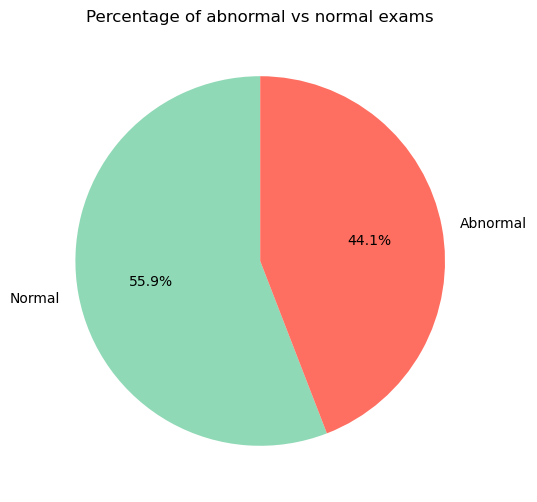

In [37]:
# Plot pie chart of normal vs abnormal exam percentages

counts = modified['flag'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    counts,
    labels=['Normal', 'Abnormal'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8fd9b6','#ff6f61']
)
plt.title("Percentage of abnormal vs normal exams")
plt.show()

In [38]:
# Print final number of unique labels remaining

print(modified['label'].nunique())   

81


In [39]:
# Print percentage of missing values per column in modified dataframe

print("Percentage of missing values in modified dataframe:")
missing_percentage = modified.isnull().mean() * 100
print(missing_percentage)



Percentage of missing values in modified dataframe:
hadm_id              0.0
charttime            0.0
valuenum             0.0
valueuom             0.0
ref_range_lower      0.0
ref_range_upper      0.0
flag                 0.0
label                0.0
fluid                0.0
examination_group    0.0
analysis_batch_id    0.0
dtype: float64


In [40]:
# Compute observed min/max per label and merge with reference ranges for inspection

exam_min_max = (
    modified.groupby('label')['valuenum']
    .agg(['min', 'max'])
    .reset_index()
)

ref_ranges = (
   modified[['label', 'ref_range_lower', 'ref_range_upper','valueuom']]
    .drop_duplicates('label')  
)

exam_min_max = exam_min_max.merge(ref_ranges, on='label', how='left')

print(exam_min_max)



                        label    min      max  ref_range_lower  \
0     Absolute Basophil Count   0.00     0.66             0.01   
1   Absolute Eosinophil Count   0.00     1.50             0.04   
2   Absolute Lymphocyte Count   0.00  3825.00             1.20   
3     Absolute Monocyte Count   0.00     3.11             0.20   
4   Absolute Neutrophil Count   0.32    41.66             1.60   
..                        ...    ...      ...              ...   
76                  WBC Count   2.00    12.40             4.00   
77          White Blood Cells   0.40   234.90             4.00   
78                       pCO2  10.00   144.00            35.00   
79                         pH   6.94     7.70             7.35   
80                        pO2  17.00   549.00            85.00   

    ref_range_upper valueuom  
0              0.08     K/uL  
1              0.54     K/uL  
2              3.70     K/uL  
3              0.80     K/uL  
4              6.10     K/uL  
..              ...  

In [41]:
# Normalize valuenum to reference range scale into 'valuenum_norm' and drop ref_range cols

range_width = modified['ref_range_upper'] - modified['ref_range_lower']

modified['valuenum_norm'] = np.where(
    range_width > 0,
    (modified['valuenum'] - modified['ref_range_lower']) / range_width,
     np.nan 
)

modified = modified.drop(columns=['ref_range_lower', 'ref_range_upper'])

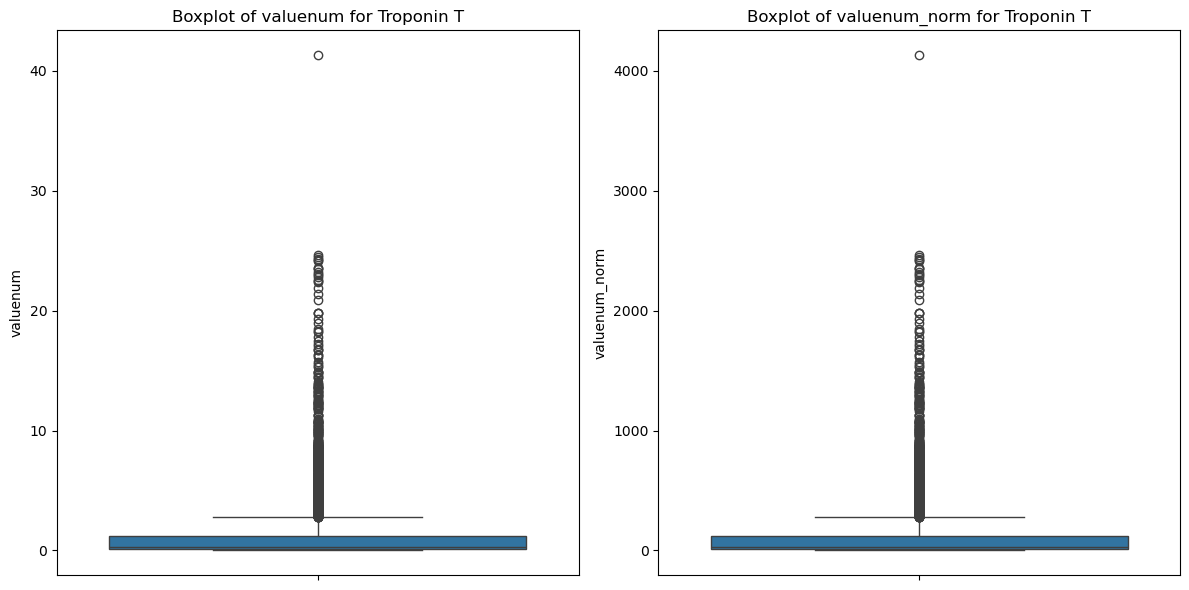

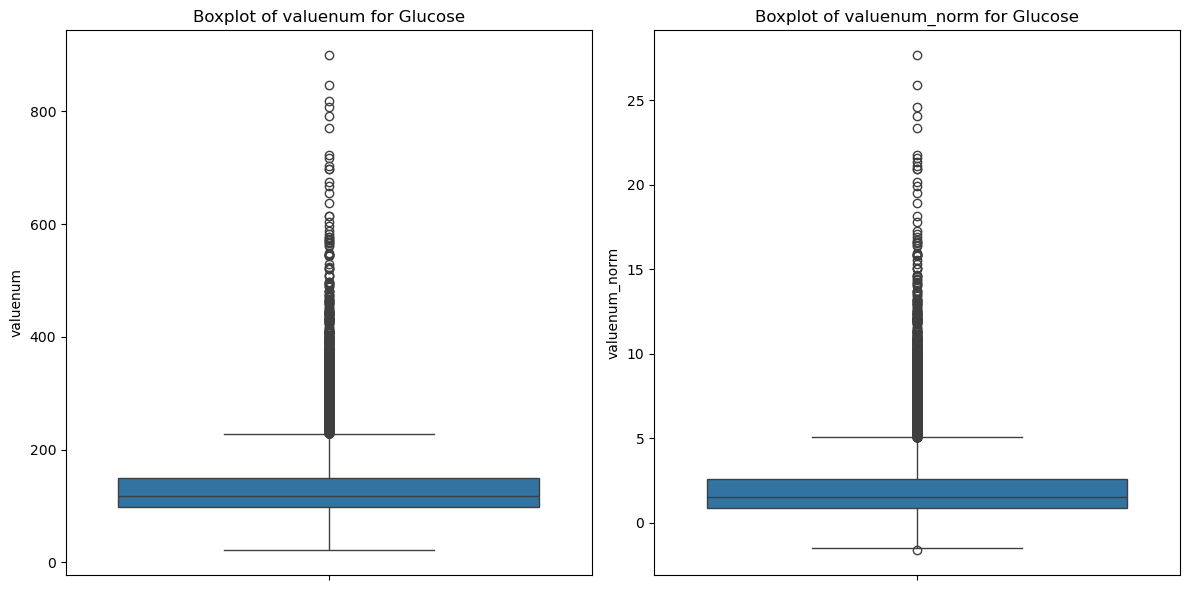

In [42]:
# Plot boxplots of valuenum and valuenum_norm for Troponin T and Glucose

import matplotlib.pyplot as plt
import seaborn as sns
exam_labels = ['Troponin T', 'Glucose']
for label in exam_labels:
    exam_data = modified[modified['label'] == label]
    
    plt.figure(figsize=(12, 6))
    
    # Boxplot for valuenum
    plt.subplot(1, 2, 1)
    sns.boxplot(y=exam_data['valuenum'])
    plt.title(f'Boxplot of valuenum for {label}')
    
    # Boxplot for valuenum_norm
    plt.subplot(1, 2, 2)
    sns.boxplot(y=exam_data['valuenum_norm'])
    plt.title(f'Boxplot of valuenum_norm for {label}')
    
    plt.tight_layout()
    plt.show()

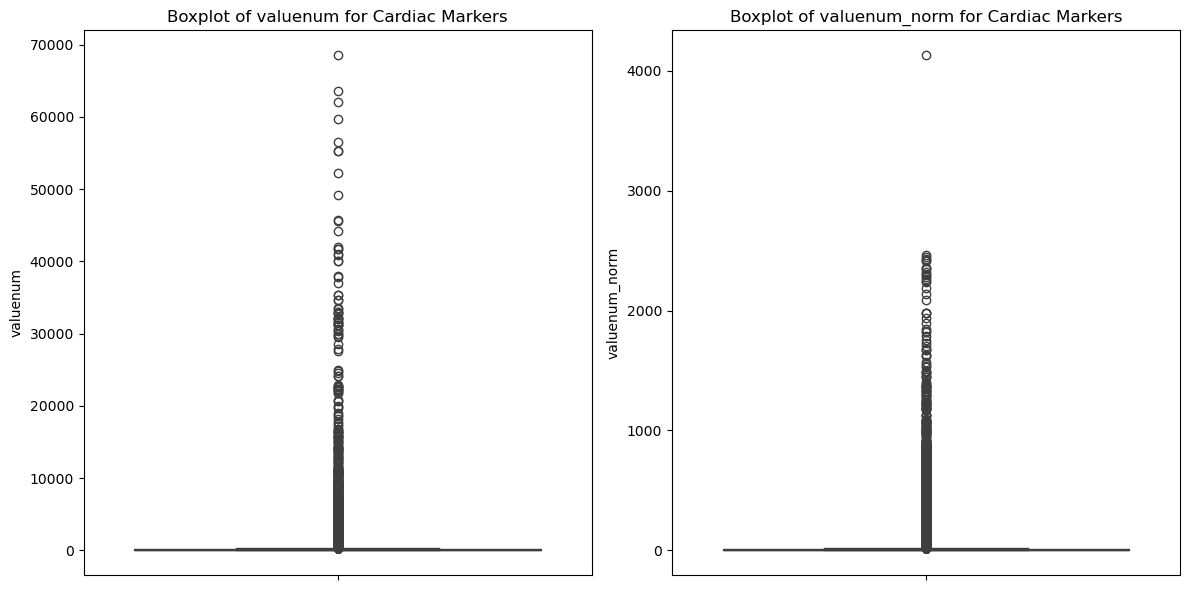

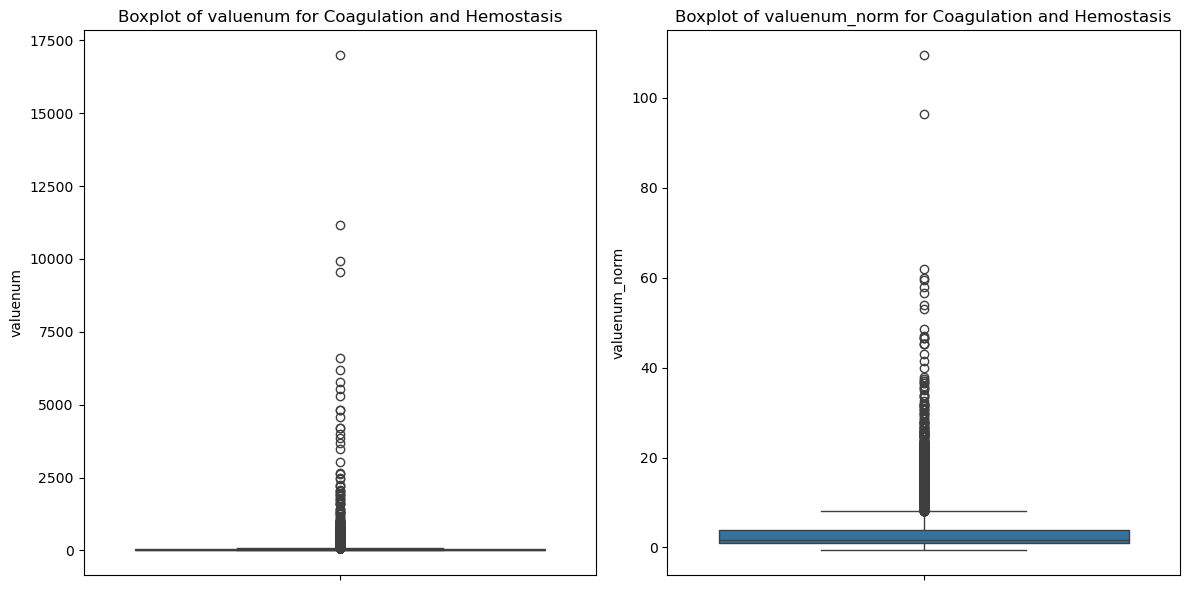

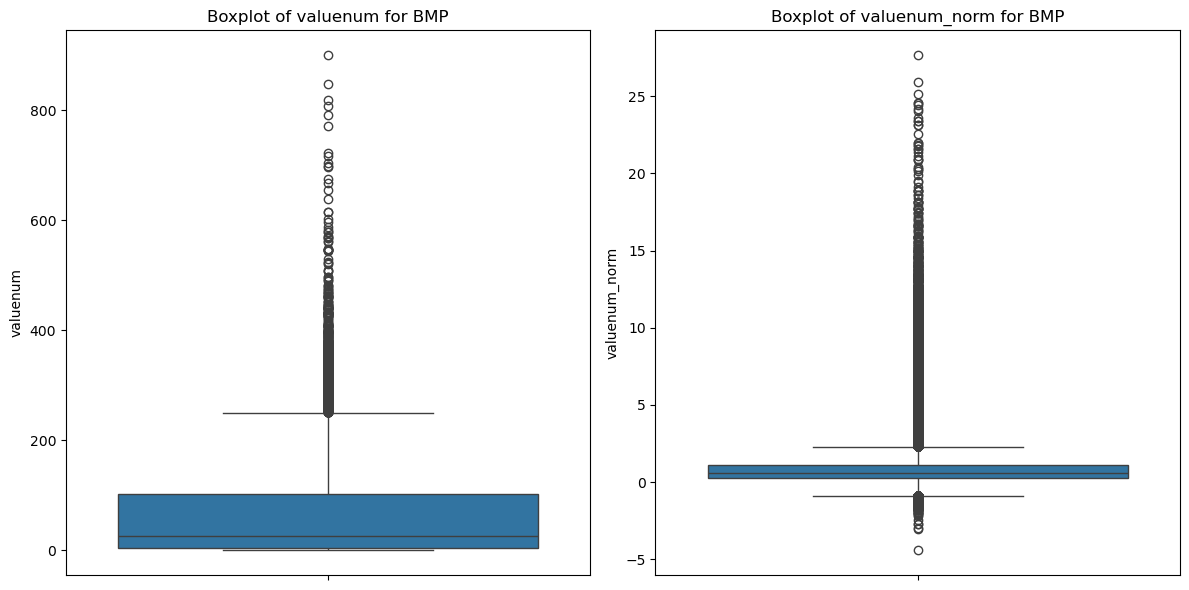

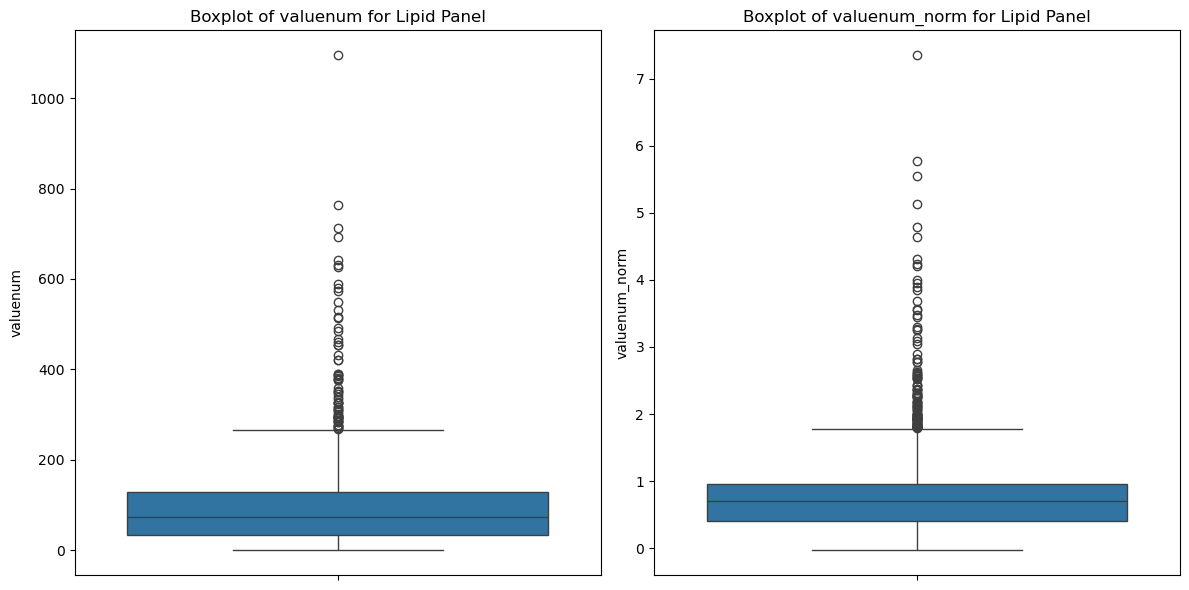

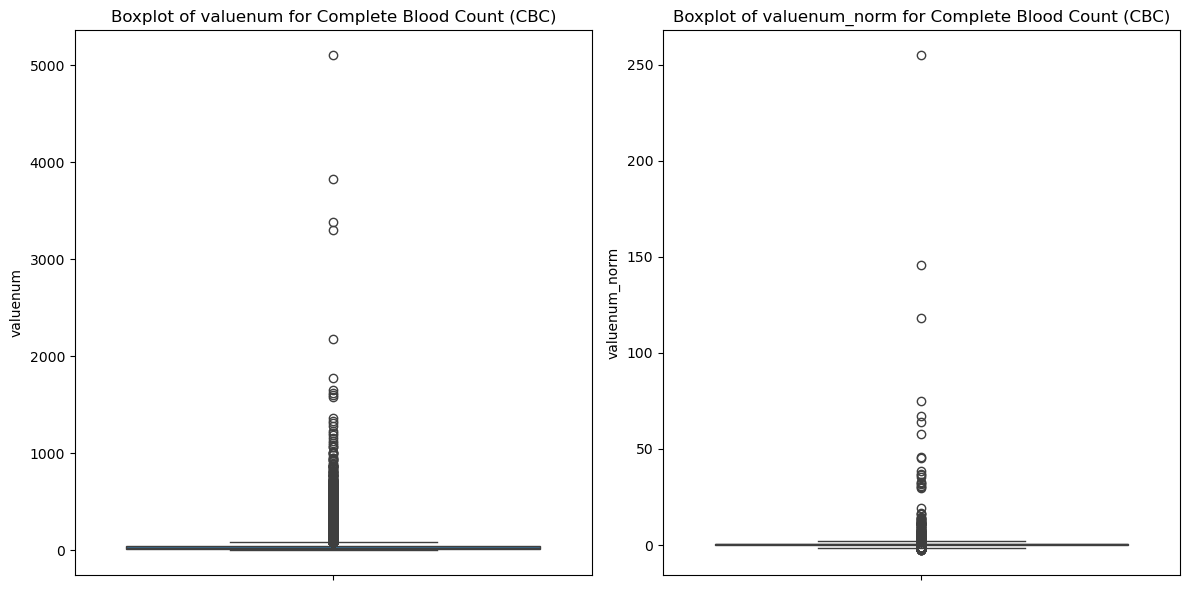

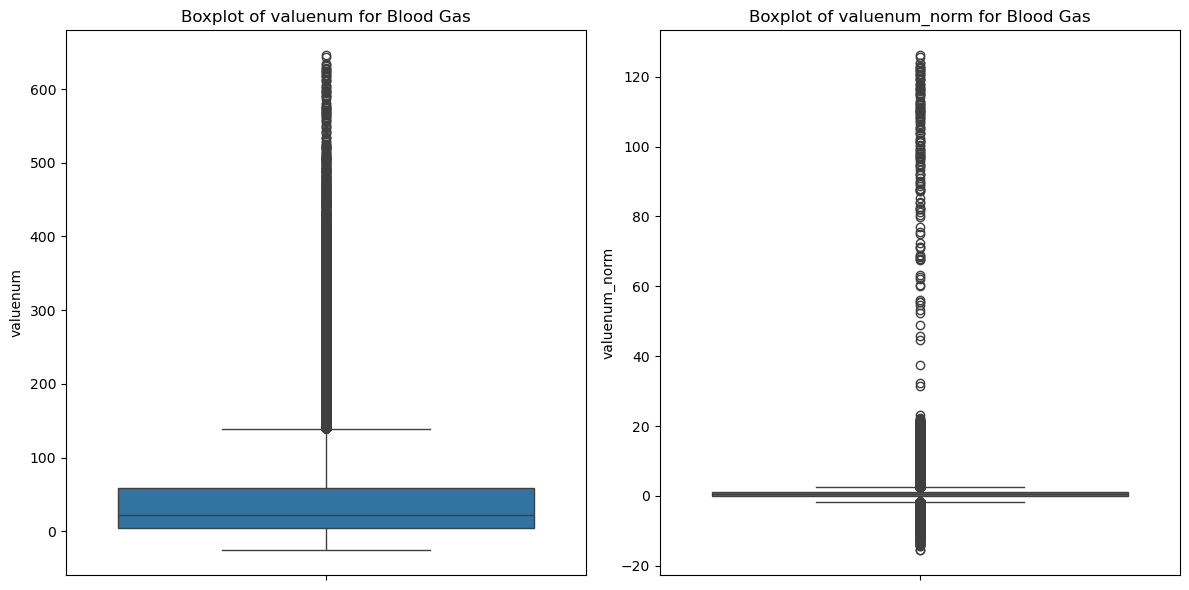

In [43]:
# Plot boxplots for each examination group comparing raw and normalized values

import matplotlib.pyplot as plt
import seaborn as sns
exam_groups = modified['examination_group'].unique()
for group in exam_groups:
    group_data = modified[modified['examination_group'] == group]
    
    plt.figure(figsize=(12, 6))
    
    # Boxplot for valuenum
    plt.subplot(1, 2, 1)
    sns.boxplot(y=group_data['valuenum'])
    plt.title(f'Boxplot of valuenum for {group}')
    
    # Boxplot for valuenum_norm
    plt.subplot(1, 2, 2)
    sns.boxplot(y=group_data['valuenum_norm'])
    plt.title(f'Boxplot of valuenum_norm for {group}')
    
    plt.tight_layout()
    plt.show()


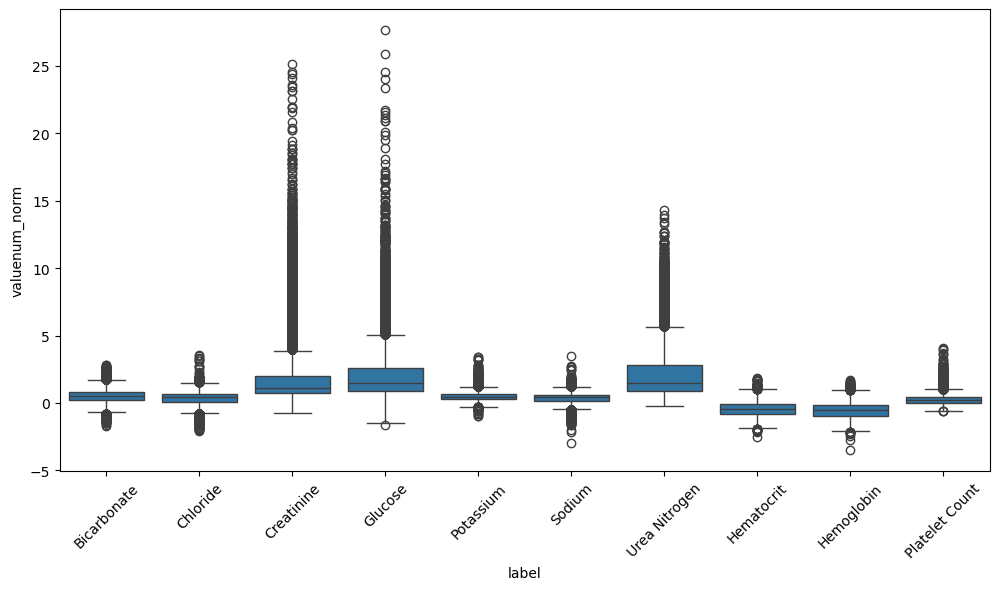

In [44]:
# Show boxplot for top 10 labels by count and save final processed CSV

counts = modified['label'].value_counts().head(10).index

subset = modified[modified['label'].isin(counts)]

plt.figure(figsize=(12,6))
sns.boxplot(x='label', y='valuenum_norm', data=subset)
plt.xticks(rotation=45)
plt.show()
#modified.drop(['ref_range_lower', 'ref_range_upper'], axis=1, inplace=True)
modified.to_csv("../../data/processed/lab_events.csv", index=False)

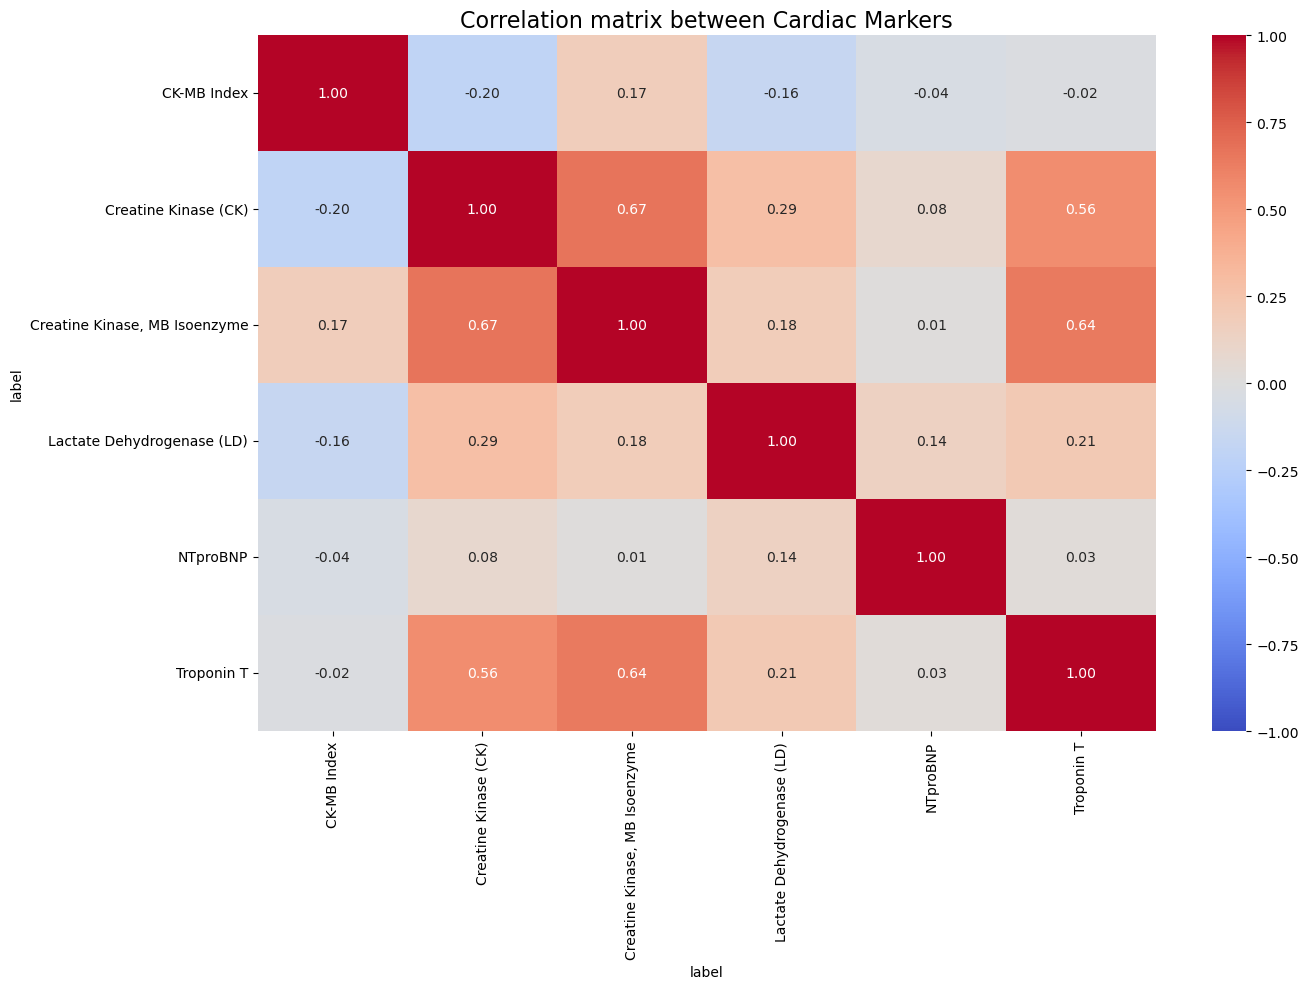

In [45]:
# Create pivot for Cardiac Markers and plot correlation heatmap between labels

subset = modified[modified['examination_group'] == 'Cardiac Markers']

# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum_norm',
    aggfunc='mean'  # If multiple values exist, take the mean
)

corr_matrix = pivot_data.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Cardiac Markers", fontsize=16)
plt.tight_layout()
plt.show()




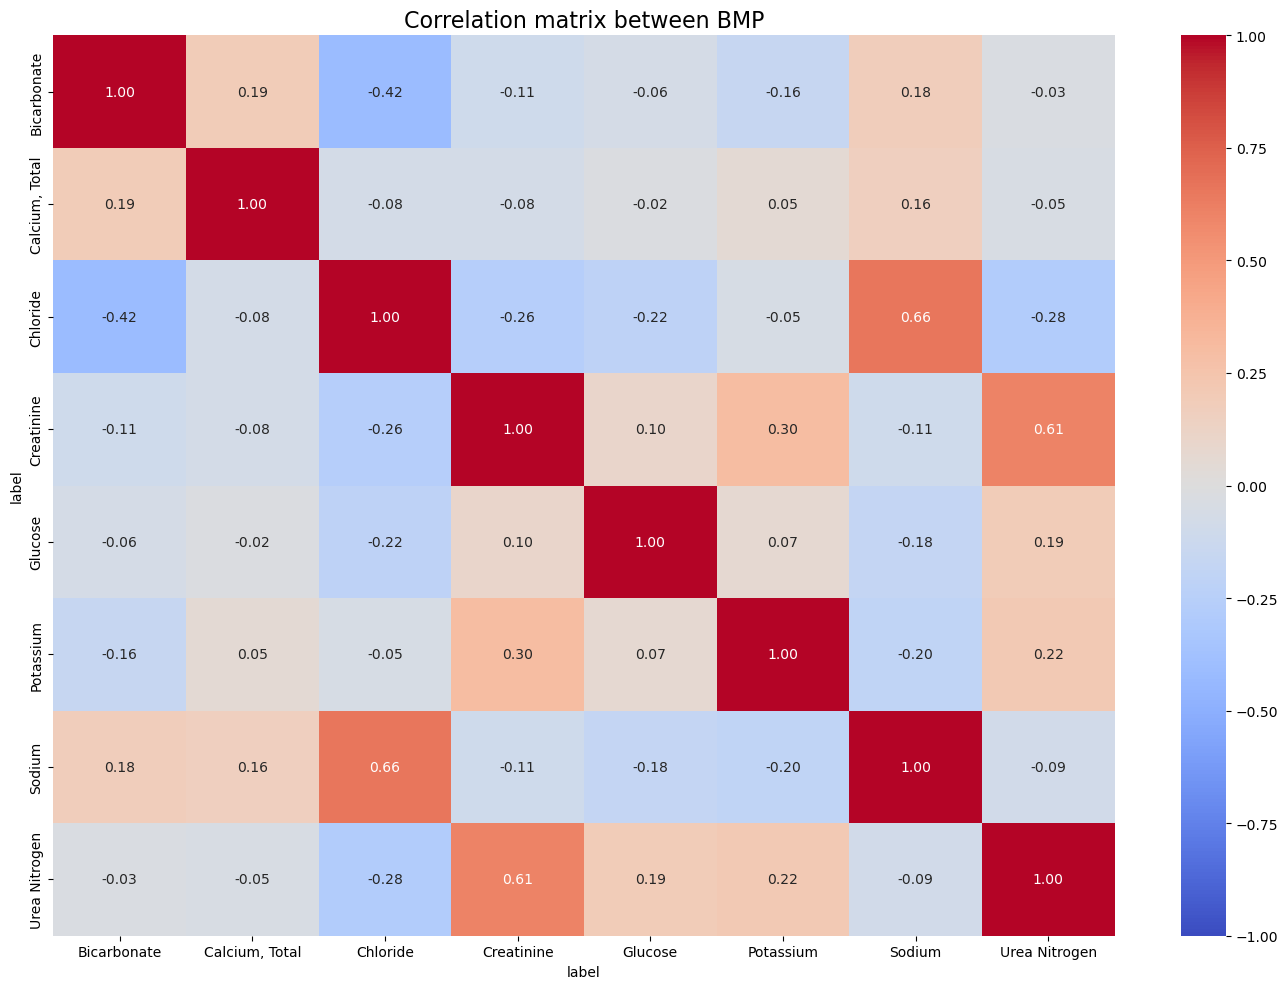

In [46]:
# Create pivot for BMP and plot correlation heatmap between labels

subset = modified[modified['examination_group'] == 'BMP']

# Pivot the data: each label becomes a column with valuenum as values
# Use subject_id and hadm_id to identify unique patient-admission combinations
pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum_norm',
    aggfunc='mean'
)

corr_matrix = pivot_data.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between BMP", fontsize=16)
plt.tight_layout()
plt.show()




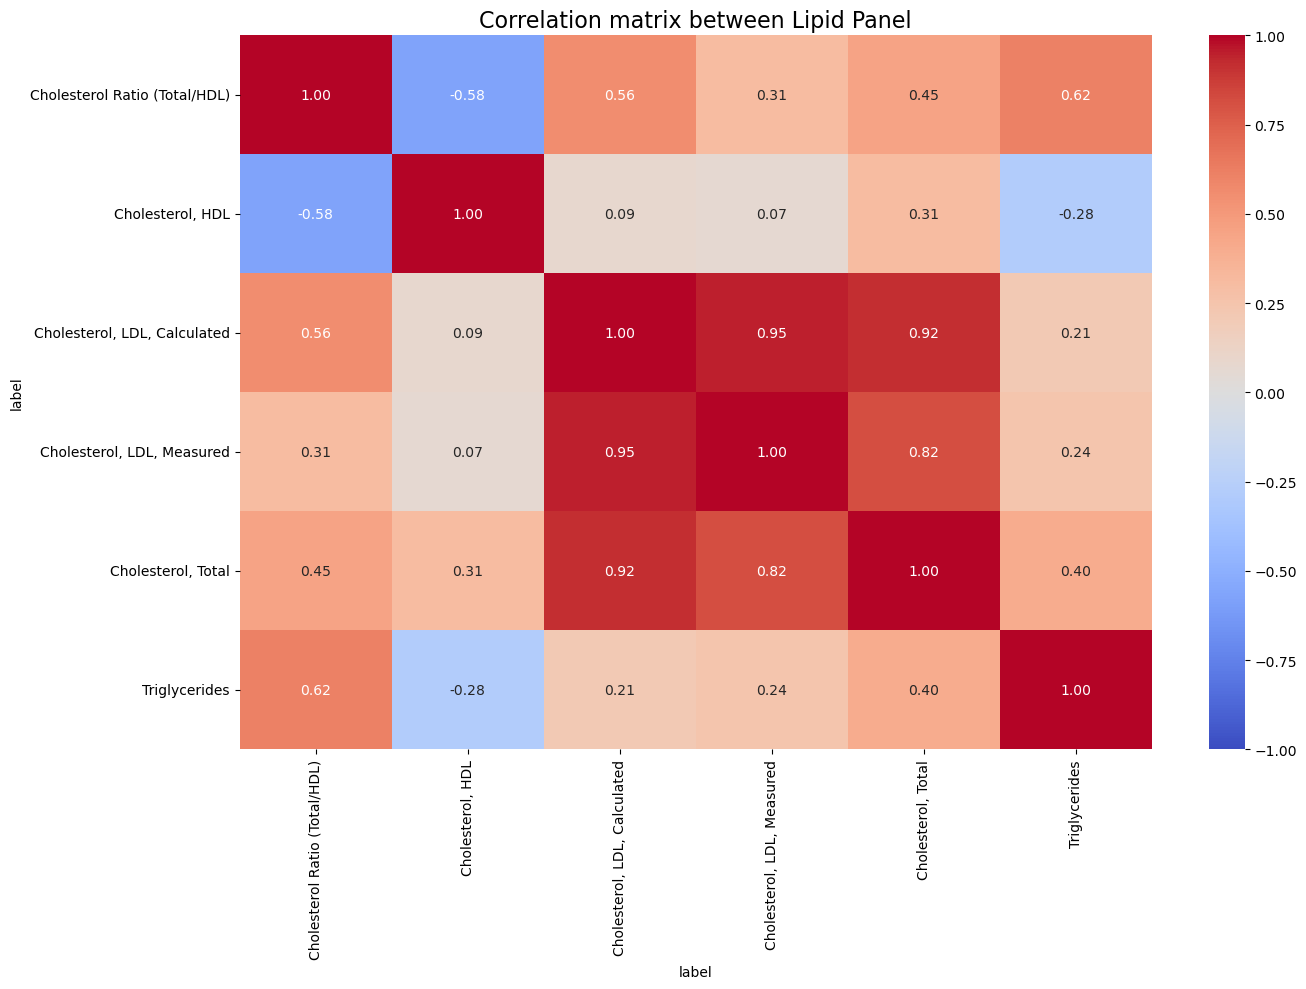

In [47]:
# Create pivot for Lipid Panel and plot correlation heatmap between labels

subset = modified[modified['examination_group'] == 'Lipid Panel']

pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum_norm',
    aggfunc='mean' 
)

corr_matrix = pivot_data.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Lipid Panel", fontsize=16)
plt.tight_layout()
plt.show()




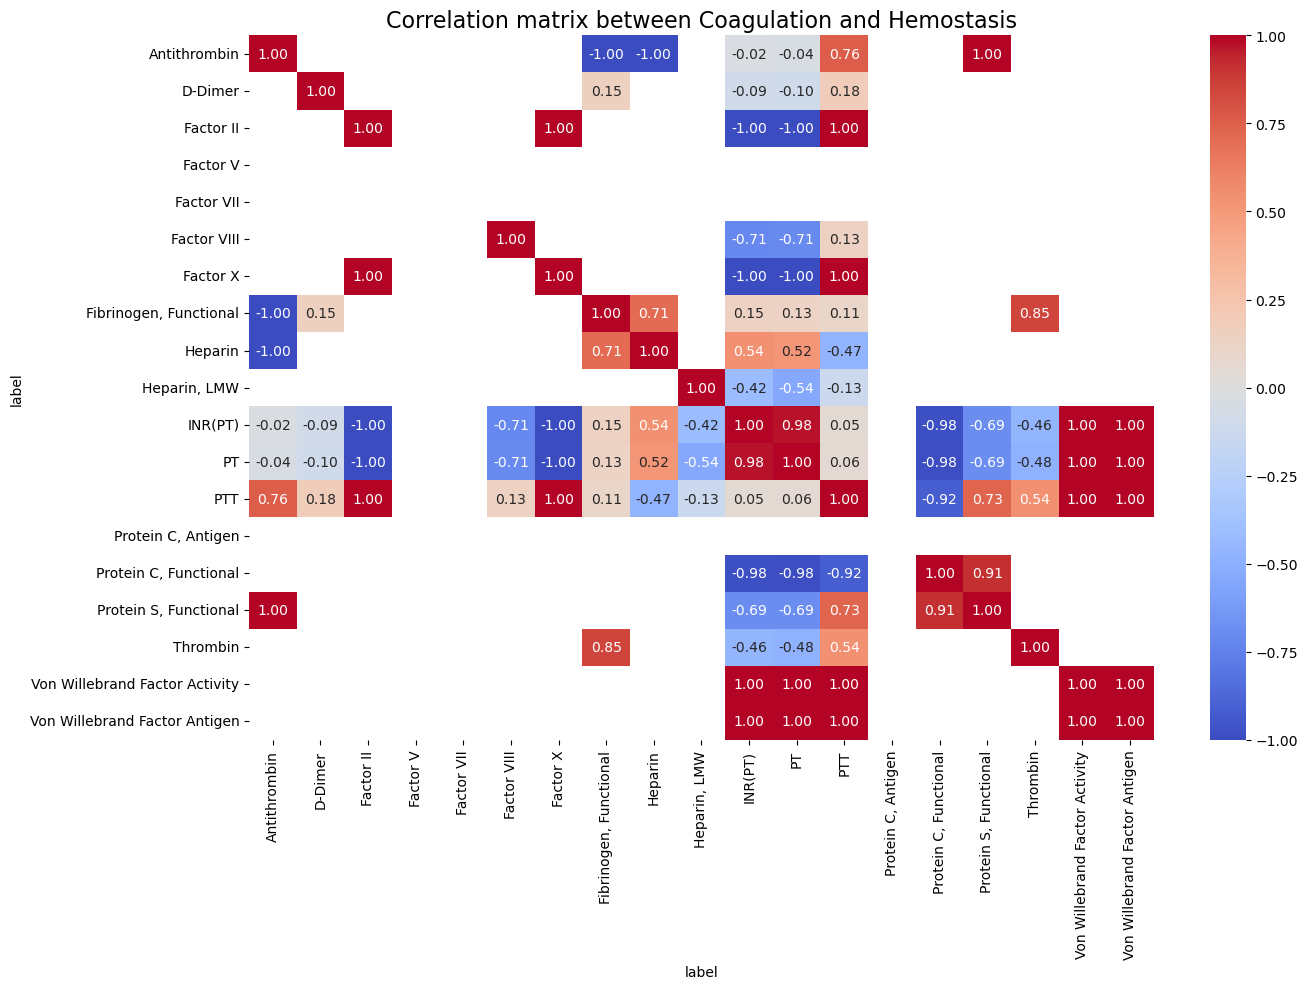

In [48]:
# Create pivot for Coagulation and Hemostasis and plot correlation heatmap
subset = modified[modified['examination_group'] == 'Coagulation and Hemostasis']

pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum_norm',
    aggfunc='mean' 
)
corr_matrix = pivot_data.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Coagulation and Hemostasis", fontsize=16)
plt.tight_layout()
plt.show()




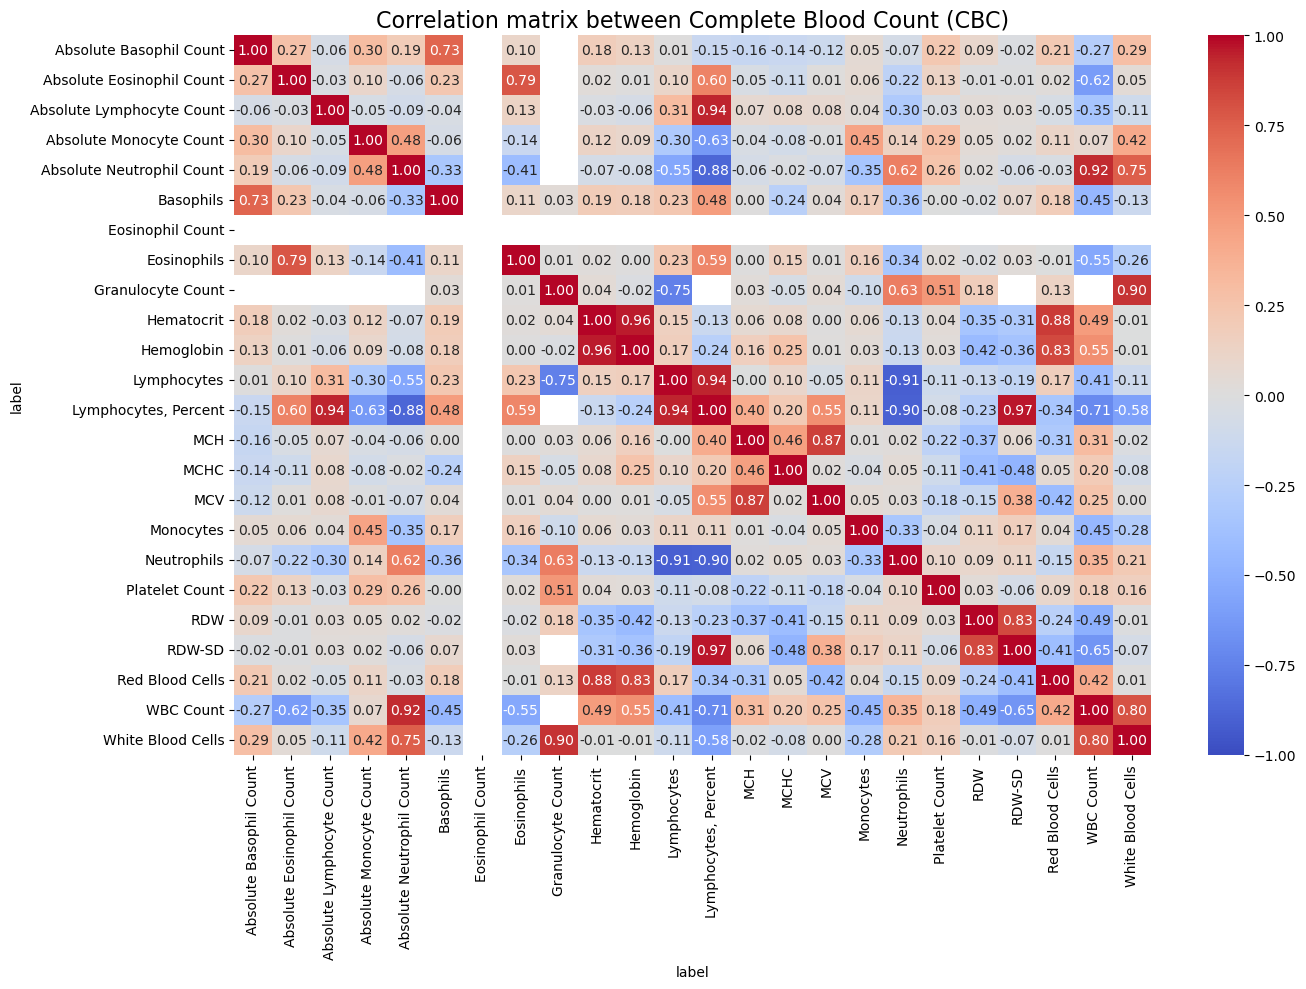

In [49]:
# Create pivot for CBC and plot correlation heatmap between labels

subset = modified[modified['examination_group'] == 'Complete Blood Count (CBC)']

pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum_norm',
    aggfunc='mean' 
)

corr_matrix = pivot_data.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Complete Blood Count (CBC)", fontsize=16)
plt.tight_layout()
plt.show()




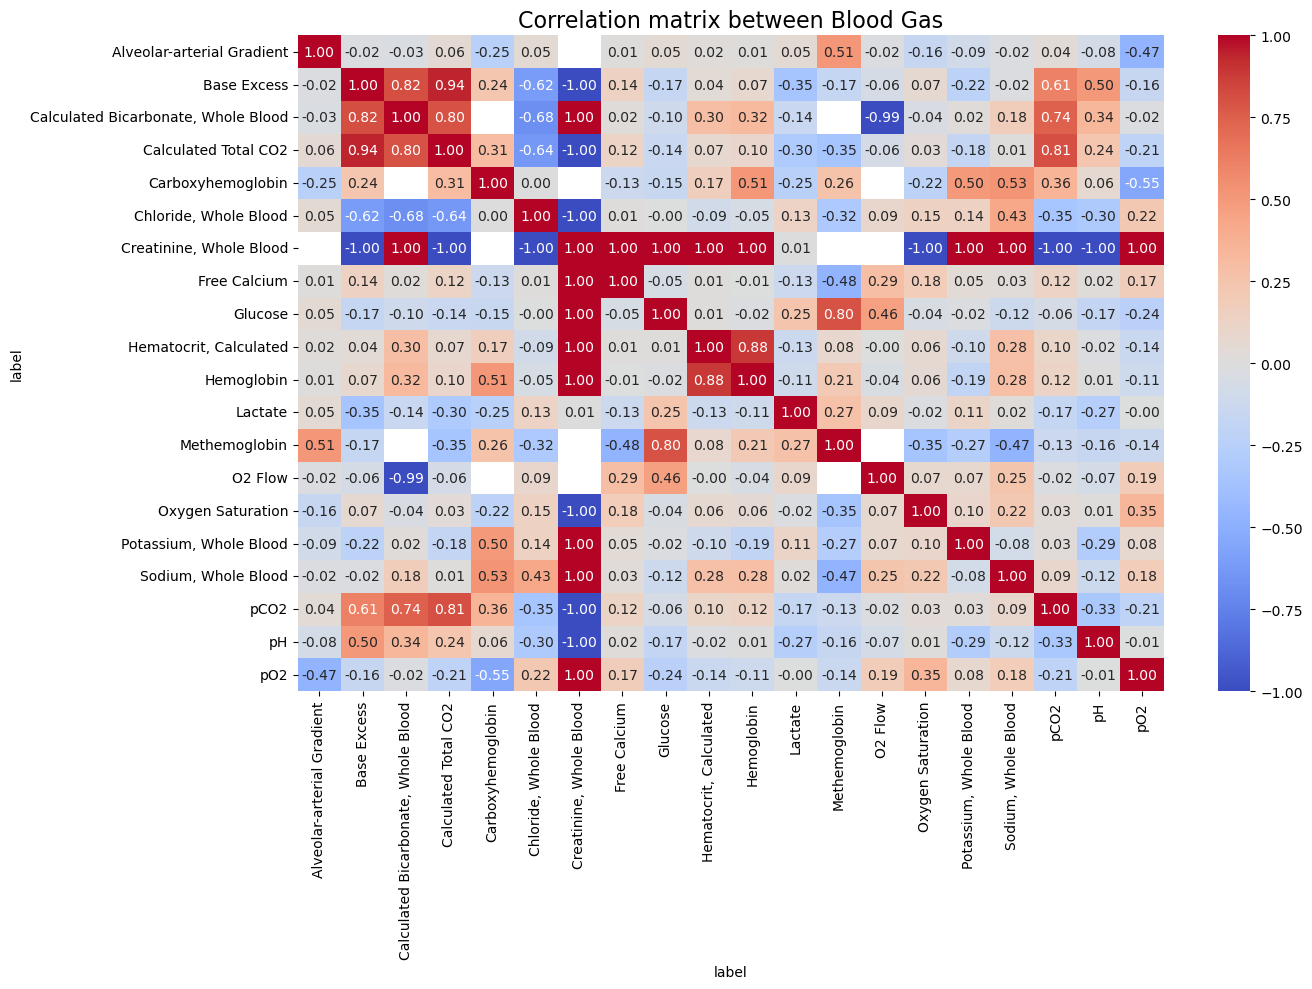

In [50]:
# Create pivot for Blood Gas and plot correlation heatmap between labels

subset = modified[modified['examination_group'] == 'Blood Gas']

pivot_data = subset.pivot_table(
    index=[ 'hadm_id'],
    columns='label',
    values='valuenum_norm',
    aggfunc='mean'  
)
corr_matrix = pivot_data.corr()

plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix between Blood Gas", fontsize=16)
plt.tight_layout()
plt.show()

In [51]:
# Drop reference range columns if still present

cols_to_drop = [c for c in ['ref_range_lower','ref_range_upper'] if c in modified.columns]
modified = modified.drop(columns=cols_to_drop)

In [52]:
# Merge final processed data with heart diagnoses to verify patient count unchanged

final_merge = pd.merge(modified, heart_diagnoses_df[['hadm_id', 'subject_id']], on='hadm_id', how='inner')
final_unique_patients = final_merge['subject_id'].nunique()

print(f"Final unique patients: {final_unique_patients}")
modified

Final unique patients: 4384


,hadm_id,charttime,valuenum,valueuom,flag,label,fluid,examination_group,analysis_batch_id,valuenum_norm
0,29654838.0,2188-01-04 23:43:00,198.00,IU/L,0,Creatine Kinase (CK),Blood,Cardiac Markers,BATCH_218801_N3,0.982558
1,29654838.0,2188-01-04 23:43:00,5.00,ng/mL,0,"Creatine Kinase, MB Isoenzyme",Blood,Cardiac Markers,BATCH_218801_C7,0.500000
2,29654838.0,2188-01-04 23:43:00,0.03,ng/mL,1,Troponin T,Blood,Cardiac Markers,BATCH_218801_R4,3.000000
3,29654838.0,2188-01-05 06:56:00,1.20,u,1,INR(PT),Blood,Coagulation and Hemostasis,BATCH_218801_K7,1.500000
5,29654838.0,2188-01-05 06:56:00,85.80,sec,1,PTT,Blood,Coagulation and Hemostasis,BATCH_218801_R1,5.286957
...,...,...,...,...,...,...,...,...,...,...
978498,21557581.0,2145-08-02 08:30:00,180.00,K/uL,0,Platelet Count,Blood,Complete Blood Count (CBC),BATCH_214508_B1,0.120000
978499,21557581.0,2145-08-02 08:30:00,14.50,%,0,RDW,Blood,Complete Blood Count (CBC),BATCH_214508_H5,0.800000
978500,21557581.0,2145-08-02 08:30:00,3.26,m/uL,1,Red Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_N7,-0.492308
978501,21557581.0,2145-08-02 08:30:00,8.40,K/uL,0,White Blood Cells,Blood,Complete Blood Count (CBC),BATCH_214508_Y6,0.733333


In [53]:
# Print number of unique labels in final dataframe

print(f"Final unique labels: {modified['label'].nunique()}")

Final unique labels: 81


In [54]:
# Print final dataframe shape and list of columns

print(f"Final dataframe shape: {modified.shape}")
print("Final dataframe columns:", modified.columns.tolist())

Final dataframe shape: (654624, 10)
Final dataframe columns: ['hadm_id', 'charttime', 'valuenum', 'valueuom', 'flag', 'label', 'fluid', 'examination_group', 'analysis_batch_id', 'valuenum_norm']
